# Frente C: clasificación (etapas 10 y 11)

Este notebook toma los **descriptores** que calcula el Frente B (una fila por época, una columna por descriptor) y los convierte en un **hipnograma**: un estadio de sueño por época. Después lo compara con el de los técnicos.

El camino completo es:

1. Expresar cada descriptor en sus unidades: potencias relativas como fracción, husos y ondas lentas como conteo por época, y EMG, EOG y LF/HF en **veces la mediana de su noche**.
2. Aplicar **reglas AASM** en orden: W, N3, REM, N2 y N1 por descarte, con la regla de **continuidad de N2**.
3. **Desempatar N1/REM con CSP** cuando la evidencia es clara (implementado, pero apagado por defecto: con datos reales empeoraba).
4. **Suavizar** el hipnograma para corregir épocas sueltas.
5. Medir el acuerdo con los técnicos: **κ de Cohen**, **F1** por estadio y **matriz de confusión**.

Todo el código está en `src/estadios/clasificacion/` (`reglas.py`, `suavizado.py`, `modelo.py`) y `src/estadios/evaluacion/metricas.py`. El notebook solo lo llama y grafica. Sin datos reales usa `tabla_sintetica()`. Las figuras se guardan en `informe/figuras/` con prefijo `c_`.

### Por qué reglas y no LDA + HMM

El anteproyecto proponía LDA y un modelo oculto de Markov. La devolución aclara que en el TP cuatrimestral la clasificación no puede usar técnicas de inteligencia artificial, y los dos lo son:

- **LDA:** ajusta medias y covarianzas con épocas etiquetadas.
- **HMM:** aprende las probabilidades de transición de los hipnogramas de entrenamiento.

Quedan como mejora para el final. En su lugar, cada umbral lo elige el diseñador mirando los histogramas de este notebook, y el suavizado usa reglas fijas de continuidad.

## Metodología: épocas, noches y pacientes

### Unidades

```
Paciente  →  1 noche (una PSG de ~8 h)  →  ~960 épocas de 30 s
```

- **Época:** un tramo de 30 s del registro. Los técnicos le asignan un estadio (W, N1, N2, N3 o REM), y es lo que clasifica el algoritmo. En la tabla de descriptores, cada época es una fila.
- **Noche:** la grabación completa de un paciente. Una hora tiene 3600 / 30 = 120 épocas, así que 8 h son unas 960. En la base HMC hay una noche por paciente, por lo que "noche", "registro" y "paciente" son lo mismo en este TP.
- **Hipnograma:** la secuencia de estadios de todas las épocas de una noche.

### Qué se hace con cada grupo de pacientes

Se usan entre 60 y 80 registros elegidos al azar de los 151 de la base, divididos 80 % para entrenamiento y 20 % para prueba.

| Paso | Con qué pacientes | Cuántas veces |
|---|---|---|
| 1. Calcular descriptores | Todos los elegidos | Una vez por paciente (`scripts/calcular_descriptores.py`); queda en caché |
| 2. Elegir los umbrales | Los de entrenamiento, **todos juntos** en los histogramas | Una sola vez, o cada vez que se revise un umbral |
| 3. Clasificar | Cada paciente **por separado** | Una vez por paciente |
| 4. Evaluar | Los de prueba | Al final |

**Paso 2, elegir los umbrales.** Primero se expresan los descriptores de cada noche en sus unidades (EMG, EOG y LF/HF relativos a la mediana de esa noche). Después se juntan las épocas de todas las noches de entrenamiento en un solo histograma por estadio. No se usa una sola noche porque:

- tiene pocas épocas de algunos estadios (N1 puede tener 20 o 30), y el cruce saldría casi al azar;
- el umbral tiene que servir para cualquier paciente, no solo para uno.

Los pacientes con más épocas de un estadio pesan más en el histograma. Si un umbral queda dudoso, conviene mirar también ese descriptor paciente por paciente.

**Paso 3, clasificar.** Para cada paciente:

1. sus descriptores se expresan en las unidades de las reglas (EMG, EOG y LF/HF relativos a la mediana de su noche);
2. se aplican las reglas con los umbrales del paso 2, que son los mismos para todos;
3. se suaviza su hipnograma.

**Paso 4, evaluar.** Se compara el hipnograma estimado de cada paciente de prueba con el de los técnicos. Se reportan el **κ global** (todas las épocas de prueba juntas, el número principal) y el **κ de cada paciente**. Los pacientes de prueba nunca se usan para elegir umbrales ni para calcular CSP; por eso el κ final es creíble.

Este notebook hace los pasos 2 a 4 solo, recorriendo las listas `entrenamiento` y `prueba`. Lo único manual es mirar los histogramas y decidir los umbrales.

## Entorno

La primera celda prepara todo antes de trabajar:

- **Se para en `codigo/`**, para que las rutas a los datos sean las mismas que usan los scripts.
- **Le dice a Python dónde está `estadios`** (`codigo/src`), por si el paquete no está instalado.
- **Crea `informe/figuras/`**, donde se guardan los gráficos.
- **Decide la fuente de datos:** si hay registros descargados, usa los reales; si no, los sintéticos.

La segunda celda define `guardar()`, que guarda cada figura como PDF en `informe/figuras/` para que el informe la incluya con `\includegraphics`.

In [53]:
# Entorno común a todos los notebooks: se corre desde codigo/ para que DIR_DATOS
# ("data" o $ESTADIOS_DATOS) apunte al mismo lugar que los scripts.
import os
import sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

# Si el paquete no está instalado con `pip install -e .`, se usa directamente codigo/src.
# Las dependencias (numpy, scipy, pandas, matplotlib, mne, scikit-learn) sí tienen que
# estar instaladas en el Python de este kernel.
try:
    import estadios  # noqa: F401
except ModuleNotFoundError:
    sys.path.insert(0, str(Path.cwd() / "src"))
FIGURAS = Path.cwd().parent / "informe" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt

from estadios.comun.config import Config
from estadios.comun.constantes import NOMBRES_ESTADIOS, N_ESTADIOS, SIN_ANOTAR
from estadios.datos.carga import ids_disponibles

USAR_DATOS_REALES = len(ids_disponibles()) > 0
print("Datos reales" if USAR_DATOS_REALES else "Sin datos descargados: se usan los sintéticos")

Sin datos descargados: se usan los sintéticos


In [54]:
def guardar(fig, nombre):
    """Guarda la figura en informe/figuras/ para incluirla con \\includegraphics."""
    fig.savefig(FIGURAS / f"{nombre}.pdf", bbox_inches="tight")

## Datos

El Frente C no trabaja con señales, sino con la **tabla de descriptores** (`TablaDescriptores`) de cada paciente:

- `matriz`: una fila por época y una columna por descriptor (potencia δ, cantidad de husos, amplitud del EMG, etc.).
- `nombres`: el nombre de cada columna, por ejemplo `"espectro.f4_delta_rel"`.
- `estadios`: lo que dijeron los técnicos en cada época.
- `covarianzas_eeg`: lo que necesita CSP.

**La partición es por paciente** (`particion_por_paciente`): 80 % entrenamiento y 20 % prueba, y todas las épocas de un paciente quedan del mismo lado. Si las épocas de un paciente estuvieran en los dos grupos, el resultado sería demasiado optimista: el clasificador se estaría evaluando con alguien que ya "conoce".

**Regla de oro:** los pacientes de prueba no se miran hasta el final. Todo lo que se decide (umbrales, filtros CSP) sale de los de entrenamiento.

**Período de sueño (decisión 3).** Las anotaciones incluyen vigilia antes de apagar y después de prender las luces. Esas épocas son fáciles de clasificar e inflarían κ, y además corren la mediana de la noche (con la que se normalizan EMG, EOG y LF/HF) hacia la vigilia. Por eso, con `SOLO_PERIODO_DE_SUENO = True`, cada tabla se recorta a las épocas entre las marcas "Lights off" y "Lights on" del archivo de anotaciones (`evaluacion/periodo.py`) antes de elegir umbrales, clasificar y evaluar. Las tablas completas quedan en `entrenamiento_completo` y `prueba_completo`, y más abajo se comparan los dos criterios. Con datos sintéticos no hay marcas y no se recorta nada.

In [55]:
from dataclasses import replace

from estadios.comun.sintetico import tabla_sintetica
from estadios.datos.particion import particion_por_paciente
from estadios.evaluacion.periodo import recortar_a_periodo_de_sueno
from estadios.pipeline import obtener_tabla

# Decisión 3: clasificar y evaluar solo entre luces apagadas y encendidas.
SOLO_PERIODO_DE_SUENO = True

cfg = Config()
if USAR_DATOS_REALES:
    ids_entrenamiento, ids_prueba = particion_por_paciente(ids_disponibles())
    # La primera vez calcula los descriptores de cada paciente y los guarda en caché.
    entrenamiento_completo = [obtener_tabla(i, cfg) for i in ids_entrenamiento]
    prueba_completo = [obtener_tabla(i, cfg) for i in ids_prueba]
else:
    entrenamiento_completo = [tabla_sintetica(semilla=s) for s in range(8)]
    prueba_completo = [tabla_sintetica(semilla=s) for s in range(100, 103)]

if SOLO_PERIODO_DE_SUENO:
    entrenamiento = [recortar_a_periodo_de_sueno(t) for t in entrenamiento_completo]
    prueba = [recortar_a_periodo_de_sueno(t) for t in prueba_completo]
else:
    entrenamiento, prueba = entrenamiento_completo, prueba_completo

print(f"Entrenamiento: {len(entrenamiento)} registros. Prueba: {len(prueba)}.")
print("Épocas de entrenamiento:", sum(len(t.estadios) for t in entrenamiento_completo), "en total,",
      sum(len(t.estadios) for t in entrenamiento), "usadas.")

Entrenamiento: 8 registros. Prueba: 3.


### Distribución de estadios

Cuenta qué fracción de las épocas es W, N1, N2, N3 y REM. Importa porque los estadios están muy desbalanceados: en datos reales N2 suele ser cerca de la mitad de la noche y N1 menos del 10 %.

Por eso **no se usa la exactitud** (porcentaje de aciertos). Un clasificador que dijera "N2" siempre acertaría la mitad sin saber nada. Para eso están κ y el F1 por estadio.

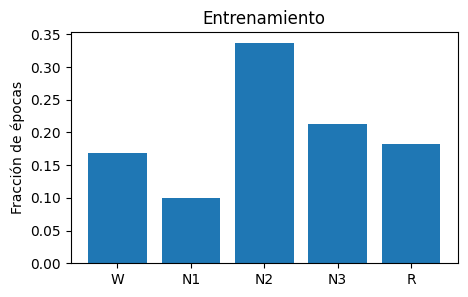

In [56]:
y_entrenamiento = np.concatenate([t.estadios for t in entrenamiento])
anotadas = y_entrenamiento != SIN_ANOTAR
conteo = np.bincount(y_entrenamiento[anotadas], minlength=N_ESTADIOS)
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(NOMBRES_ESTADIOS, conteo / conteo.sum())
ax.set(ylabel="Fracción de épocas", title="Entrenamiento")
guardar(fig, "c_distribucion_estadios")

## Elección de los umbrales

Esta es la parte central del Frente C.

### Unidades de cada descriptor

`reglas.descriptores_de_reglas()` busca en la tabla los siete descriptores que usan las reglas y expresa cada uno en las unidades con que se interpreta:

| Descriptor | Unidad en las reglas | Por qué |
|---|---|---|
| δ relativa (F4), α relativa (O2) | Fracción de la potencia total, de 0 a 1 | Ya es relativa: no depende de la amplitud del paciente |
| Husos, ondas lentas | Cantidad de eventos en la época de 30 s | Es un conteo con criterio absoluto, como en la AASM |
| EMG, EOG, LF/HF | **Veces la mediana de la noche** (1 = lo típico de ese paciente) | Dependen de la amplitud y del electrodo: un paciente puede tener el doble de µV que otro |

Así, "EMG ≤ 0,7" significa "tono muscular por debajo del 70 % de lo típico en la noche de ese paciente", y "ondas ≥ 3" significa "al menos 3 ondas lentas detectadas en la época".

**Cómo se calcula "veces la mediana" (`reglas.veces_la_mediana`).** El Frente B entrega EMG, EOG y LF/HF en $\log_{10}$. Se resta la mediana de la noche y se deshace el logaritmo:

$$\text{veces la mediana} = 10^{\,x - \operatorname{mediana}(x)}$$

La mediana no se ve afectada por los valores extremos, como un artefacto de movimiento. Las épocas sin valor (NaN) no cumplen ninguna regla.

### Por qué no se usan percentiles

La primera versión expresaba **todos** los descriptores como percentil dentro de la noche. Con los 70 registros reales dio κ = 0,245. El problema es estructural: un umbral como "δ ≥ percentil 70" fija qué **fracción** de cada noche puede cumplir la regla (el 30 % de las épocas), tenga el paciente mucho N3 o casi nada. En pacientes con poco N3, el 30 % de la noche con más δ incluía vigilia y N2, y 364 épocas de vigilia terminaron clasificadas como N3. Por eso ahora solo se normalizan por paciente los descriptores que dependen de la amplitud, y sin forzar ninguna proporción.

### Los histogramas

Cada regla separa un estadio de los que más se le parecen. Para cada una se grafican dos histogramas superpuestos, con los pacientes de entrenamiento: el descriptor en el estadio que la regla detecta y en los estadios de los que lo tiene que separar. Por ejemplo, para `n3_delta_min`: la δ relativa en épocas N3 contra épocas N2.

- **Línea punteada:** `cruce_de_histogramas()`, el punto donde se cruzan los dos histogramas. Es el umbral que menos errores comete en esa comparación.
- **Línea roja:** el umbral actual de `ConfigClasificacion`.
- EMG, EOG y LF/HF se grafican en escala logarítmica, porque "la mitad" y "el doble" de lo típico están a la misma distancia del 1.

**Cómo se usa:** mirás el gráfico, decidís el valor y lo copiás en `src/estadios/comun/config.py`. Después reiniciás el kernel y volvés a correr el notebook.

**Por qué no es IA:** ningún algoritmo prueba combinaciones de umbrales para maximizar el acierto. El umbral lo elige una persona mirando un gráfico, igual que la frecuencia de corte de un filtro. La tabla al final de la celda resume el umbral actual y el cruce de cada regla.

,umbral,actual,cruce
0,w_emg_min,60.0,75.0
1,w_alfa_min,60.0,79.0
2,n3_delta_min,70.0,76.9
3,n3_ondas_min,70.0,75.5
4,r_emg_max,35.0,31.7
5,r_eog_min,60.0,71.0
6,r_lf_hf_min,75.0,71.0
7,n2_husos_min,50.0,59.0


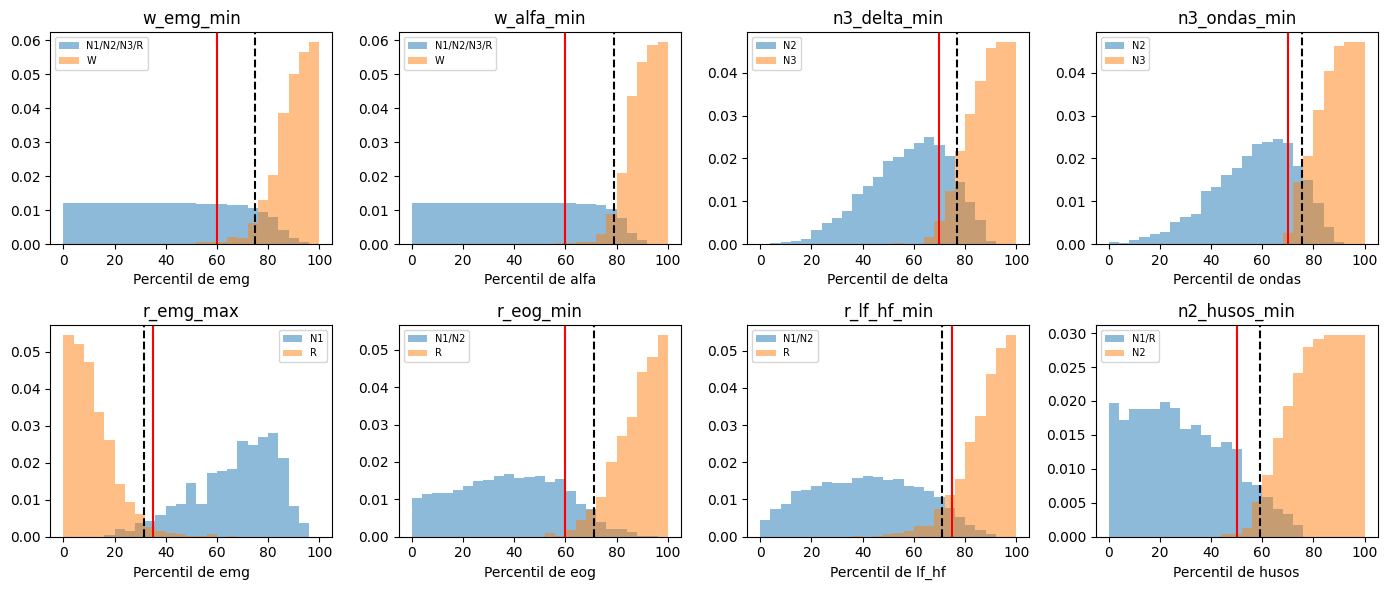

In [57]:
from estadios.clasificacion import reglas
from estadios.comun.constantes import N1, N2, N3, R, W

# Descriptores de todas las épocas de entrenamiento, en las unidades de las reglas.
por_tabla = [reglas.descriptores_de_reglas(t.matriz, t.nombres, cfg.clasificacion) for t in entrenamiento]
V = {k: np.concatenate([v[k] for v in por_tabla]) for k in por_tabla[0]}
Y = y_entrenamiento

c = cfg.clasificacion
UNIDADES = {"emg": "veces la mediana", "eog": "veces la mediana", "lf_hf": "veces la mediana",
            "alfa": "fracción", "delta": "fracción", "ondas": "ondas por época", "husos": "husos por época"}
# (descriptor, estadio que detecta, estadios de los que lo separa, campo del umbral)
UMBRALES = [
    ("emg",   [W],  [N1, N2, N3, R], "w_emg_min"),
    ("alfa",  [W],  [N1, N2, N3, R], "w_alfa_min"),
    ("eog",   [W],  [N1, N2, N3],    "w_eog_min"),
    ("delta", [N3], [N2],            "n3_delta_min"),
    ("ondas", [N3], [N2],            "n3_ondas_min"),
    ("emg",   [R],  [N1],            "r_emg_max"),
    ("eog",   [R],  [N1, N2],        "r_eog_min"),
    ("lf_hf", [R],  [N1, N2],        "r_lf_hf_min"),
    ("husos", [N2], [N1, R],         "n2_husos_min"),
]
UMBRALES = [u for u in UMBRALES if u[0] in V]

fig, axs = plt.subplots(3, 3, figsize=(14, 10))
filas = []
for ax, (clave, si, no, campo) in zip(axs.flat, UMBRALES):
    a, b = V[clave][np.isin(Y, si)], V[clave][np.isin(Y, no)]
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    actual = getattr(c, campo)
    if clave in reglas.RELATIVOS_A_LA_NOCHE:
        # En log10: el cruce se calcula ahí y se vuelve a veces la mediana.
        cruce = 10 ** reglas.cruce_de_histogramas(np.log10(a), np.log10(b))
        bins = np.logspace(*np.log10(np.percentile(np.r_[a, b], [0.5, 99.5])), 40)
        ax.set_xscale("log")
    elif clave in ("husos", "ondas"):
        tope = np.percentile(np.r_[a, b], 99)
        bins = np.arange(-0.5, tope + 1.5)
        cruce = reglas.cruce_de_histogramas(a, b, bins=len(bins) - 1)
    else:
        bins = np.linspace(*np.percentile(np.r_[a, b], [0.5, 99.5]), 40)
        cruce = reglas.cruce_de_histogramas(a, b)
    ax.hist(b, bins, density=True, alpha=0.5, label="/".join(NOMBRES_ESTADIOS[e] for e in no))
    ax.hist(a, bins, density=True, alpha=0.5, label="/".join(NOMBRES_ESTADIOS[e] for e in si))
    ax.axvline(cruce, ls="--", c="k")
    ax.axvline(actual, c="r")
    ax.set(title=campo, xlabel=f"{clave} ({UNIDADES[clave]})")
    ax.legend(fontsize=7)
    filas.append({"umbral": campo, "unidad": UNIDADES[clave], "actual": actual, "cruce": round(float(cruce), 3),
                  f"mediana del estadio": round(float(np.median(a)), 3), "mediana de los otros": round(float(np.median(b)), 3)})
for ax in axs.flat[len(UMBRALES):]:
    ax.axis("off")
fig.tight_layout()
guardar(fig, "c_eleccion_umbrales")

import pandas as pd
pd.DataFrame(filas)

## Clasificación de los pacientes de prueba

`ModeloEstadios` (en `modelo.py`) une todas las piezas:

- **`ajustar(entrenamiento)`** solo calcula los filtros CSP (ver 5b). Las reglas no se entrenan.
- **`predecir(tabla)`** hace tres cosas en orden: reglas, desempate CSP y suavizado.


### 5a. Reglas (`reglas.aplicar_reglas`)

Se evalúan en orden, y cada época se queda con la **primera** que cumple:

| Orden | Estadio | Condición | Por qué |
|---|---|---|---|
| 1 | W | EMG alto **y** (α alta **o** EOG alto) | Despierto: tono muscular, y ritmo α (ojos cerrados) o parpadeos (ojos abiertos) |
| 2 | N3 | δ relativa alta **y** al menos algunas ondas lentas | Sueño profundo: ondas lentas grandes |
| 3 | REM | EMG bajo **y** (EOG alto **o** LF/HF alto) **y** ningún huso | Atonía y movimientos oculares |
| 4 | N2 | al menos un huso | Los husos caracterizan N2 |
| 5 | N1 | ninguna de las anteriores | Estadio de transición, definido por descarte |

El orden importa. W y N3 van primero porque son los más fáciles de reconocer. REM va antes que N2 porque su EEG se parece al de N1, y lo que lo distingue es el EMG y el EOG.

**Vigilia con ojos abiertos.** Con los ojos abiertos casi no hay ritmo α, y en los datos reales una parte de la vigilia tenía α muy baja. Por eso W acepta, en lugar de α, parpadeos: EOG muy alto.

**Continuidad de N2 (`reglas.continuidad_n2`).** Con datos reales, 1396 épocas N2 terminaban en N1: no tenían husos y caían por descarte. La AASM tiene una regla para esto: el sueño N2 continúa, aunque la época no tenga husos, hasta que algo lo interrumpe (un despertar, movimientos oculares, ondas lentas). Por eso, una época que quedó en N1 por descarte y sigue a una N2 pasa a N2, y la continuidad se propaga por varias épocas seguidas. En el gráfico de uso de reglas aparece como "N2 cont.". Se activa con `continuidad_n2 = True`.

### 5b. Desempate N1/REM con CSP (`reglas.desempatar_con_csp`)

**Apagado por defecto.** Con los datos reales, el desempate cambió unas 900 épocas de prueba y acertó solo en el 9 %: N1 y REM se superponen casi por completo en el puntaje CSP (ver la figura de la subsección en detalle). Por eso `"csp"` no está en `grupos` por defecto. La hipótesis H3 lo prende para medir su efecto, y ese resultado negativo es válido para el informe. Lo que sigue describe cómo funciona cuando está activo.

N1 y REM son el par que más se confunde. CSP combina los cuatro canales de EEG en una señal cuya potencia es alta cuando la época se parece a N1 y baja cuando se parece a REM.

- Si una época quedó como REM pero su puntaje CSP está **claramente** del lado de N1 (a más de un ancho típico de cada estadio del punto medio entre los dos), pasa a N1. Y al revés.
- Si la evidencia no es clara, no se toca.


El detalle está en la subsección siguiente, que se puede plegar.

#### Desempate CSP en detalle

##### Por qué combinar canales puede separar N1 de REM

Cada canal de EEG (F4, C4, O2 y C3) mira una zona distinta del cerebro. Mirando **un canal solo**, N1 y REM se parecen mucho: actividad de baja amplitud y frecuencias mixtas. Por eso se confunden.

Lo que difiere entre los dos estadios puede estar en **cómo se reparte la potencia entre las zonas**:

- En N1 suelen quedar restos de ritmo α en la zona occipital (O2) y aparecen ondas agudas en el vértex (zona central).
- En REM aparecen ondas en diente de sierra centrales y más contaminación de los movimientos oculares en los electrodos frontales.

Cada diferencia es chica en un canal suelto, pero sumando los canales con los pesos adecuados se pueden reforzar. Eso hace CSP: **busca la combinación de canales donde la diferencia de potencia entre N1 y REM es máxima**. No hace falta saber de antemano cuál es la diferencia fisiológica; CSP la encuentra en los datos de entrenamiento.

##### Paso 1: la señal combinada

CSP calcula un peso para cada canal, $\mathbf{w} = (w_{F4}, w_{C4}, w_{O2}, w_{C3})$, y arma una señal nueva:

$$s(t) = w_{F4}\,\text{F4}(t) + w_{C4}\,\text{C4}(t) + w_{O2}\,\text{O2}(t) + w_{C3}\,\text{C3}(t)$$

Su potencia en una época se calcula con la **matriz de covarianza** de los cuatro canales en esa época, $\mathbf{C}$, que el Frente B guarda en `covarianzas_eeg`:

$$P = \mathbf{w}^\top \mathbf{C}\, \mathbf{w}$$

$\mathbf{C}$ tiene en la diagonal la potencia de cada canal y, fuera de la diagonal, cuánto se mueven juntos dos canales. Con eso alcanza para calcular la potencia de cualquier combinación sin volver a la señal.

##### Paso 2: cómo se eligen los pesos (`csp.ajustar_csp`)

Con las épocas de **entrenamiento** se calcula la covarianza promedio de cada estadio:

- $\mathbf{C}_{N1}$: el promedio de las matrices de todas las épocas N1;
- $\mathbf{C}_{R}$: el promedio de las matrices de todas las épocas REM.

Después se buscan los $\mathbf{w}$ que maximizan

$$\lambda = \frac{\mathbf{w}^\top \mathbf{C}_{N1}\,\mathbf{w}}{\mathbf{w}^\top (\mathbf{C}_{N1} + \mathbf{C}_{R})\,\mathbf{w}}$$

que es **qué fracción de la potencia total de la señal combinada aparece en N1**:

- $\lambda$ cerca de 1: mucha potencia en N1 y casi nada en REM.
- $\lambda$ cerca de 0: al revés, mucha en REM y casi nada en N1.
- $\lambda = 0{,}5$: la combinación no distingue los estadios.

El problema tiene solución exacta: es un **problema de autovalores generalizado**, $\mathbf{C}_{N1}\mathbf{w} = \lambda(\mathbf{C}_{N1}+\mathbf{C}_{R})\mathbf{w}$. Con 4 canales da 4 soluciones, ordenadas de menor a mayor $\lambda$. Se usan las de los **dos extremos**, que son las que más separan. Con `componentes_csp = 2` son 4 filtros: los 2 de $\lambda$ más bajo (marcan REM) y los 2 de $\lambda$ más alto (marcan N1).

Es álgebra lineal, de la misma familia que el análisis espacial visto en clase. No hay un entrenamiento iterativo.

##### Paso 3: el puntaje de cada época (`reglas.puntaje_csp`)

Para cada época se calcula la potencia de cada filtro, en logaritmo, y se resta:

$$\text{puntaje} = \text{prom}\left(\log P_{\text{filtros N1}}\right) - \text{prom}\left(\log P_{\text{filtros REM}}\right)$$

- **Puntaje alto:** la época se parece a N1.
- **Puntaje bajo:** se parece a REM.

El logaritmo hace que importen las proporciones y no los valores absolutos: una época con el doble de potencia en todos los canales tiene el mismo puntaje.

##### Paso 4: dónde cortar (`reglas.referencia_csp`)

Con las épocas de entrenamiento se calculan dos números:

- **Centro:** el punto medio entre la mediana del puntaje en N1 y la mediana en REM. Es la frontera entre los dos estadios.
- **Escala:** el ancho típico de cada estadio: el promedio entre el rango intercuartil (el ancho del 50 % central) de los puntajes N1 y el de los puntajes REM. Sirve para medir la distancia al centro en unidades comparables.

  El ancho se mide **dentro de cada estadio** y no con los dos juntos. Mezclados, el rango intercuartil queda del tamaño de la distancia entre los dos grupos, y casi ninguna época superaría el margen.

Cada época se lleva a esa escala:

$$z = \frac{\text{puntaje} - \text{centro}}{\text{escala}}$$

##### Paso 5: el desempate (`reglas.desempatar_con_csp`)

Solo se tocan las épocas que las reglas ya asignaron a N1 o a REM. Con `csp_margen = 1`:

| La regla dijo | z | Qué pasa |
|---|---|---|
| REM | ≥ 1 (claramente del lado de N1) | Pasa a **N1** |
| N1 | ≤ −1 (claramente del lado de REM) | Pasa a **REM** |
| N1 o REM | entre −1 y 1 | No se toca |
| Otro estadio | cualquiera | No se toca |

**Por qué un margen y no el signo:** las reglas ya usan información fuerte para REM (atonía y movimientos oculares). CSP solo debería contradecirlas cuando su evidencia es muy clara. Si se usara el signo de $z$, cualquier época cerca de la frontera cambiaría de estadio por ruido.

**Ejemplo.** En entrenamiento, la mediana del puntaje fue 0,8 en N1 y −0,4 en REM, y el rango intercuartil de cada uno es 0,5 y 0,7, así que la escala es (0,5 + 0,7) / 2 = 0,6:

- centro = (0,8 + (−0,4)) / 2 = 0,2.
- Una época que las reglas llamaron REM tiene puntaje 1,1: z = (1,1 − 0,2) / 0,6 = 1,5 ≥ 1, así que pasa a **N1**.
- Otra época REM tiene puntaje 0,5: z = 0,5. No alcanza y queda en **REM**.

##### Cómo se evalúa si sirve

Es la **H3**: el notebook 04 compara el F1 de N1 y de REM con y sin el desempate, paciente por paciente, con la prueba de Wilcoxon. Además, los pesos $\mathbf{w}$ muestran **qué zona del cerebro** usa CSP para separar los estadios, algo para comentar en la discusión del informe.

##### Qué muestra la celda siguiente

- **Izquierda:** los pesos de cada filtro, normalizados. El signo no importa (la potencia de $-s$ es la misma que la de $s$); lo que cuenta es el tamaño: los canales con pesos grandes son los que más aportan a separar N1 de REM.
- **Derecha:** el $z$ de las épocas N1 y REM de entrenamiento. La línea negra es el centro y las punteadas, el margen. Las épocas que caen fuera de las punteadas, del lado contrario a su regla, son las que el desempate cambia.

Centro = -0.009, escala = 2.148, margen = 1
Épocas de prueba que cambió el desempate: 0


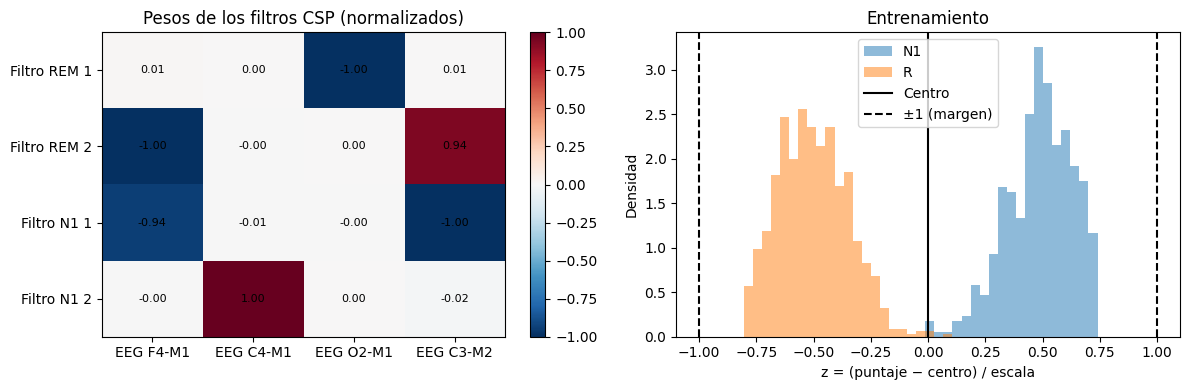

In [58]:
from estadios.clasificacion.modelo import ModeloEstadios
from estadios.comun.constantes import CANALES_EEG
from estadios.descriptores import csp

# Modelo propio de esta celda: la clasificación completa se corre más abajo.
from estadios.comun.config import GRUPOS_DESCRIPTORES

# Con CSP activo (por defecto está apagado), para ver cómo separa N1 de REM.
modelo_csp = ModeloEstadios(replace(cfg.clasificacion, grupos=GRUPOS_DESCRIPTORES)).ajustar(entrenamiento)
if not modelo_csp.filtros_csp:
    print("No hay épocas suficientes de N1 y REM para calcular CSP.")
else:
    filtro = modelo_csp.filtros_csp[0]
    centro, escala = modelo_csp.referencias_csp[0]
    margen = modelo_csp.cfg.csp_margen

    fig, axs = plt.subplots(1, 2, figsize=(12, 4))

    # Pesos de cada filtro: las primeras filas marcan REM y las últimas, N1.
    pesos = filtro.pesos / np.abs(filtro.pesos).max(axis=1, keepdims=True)
    mitad = len(pesos) // 2
    etiquetas = [f"Filtro REM {i + 1}" for i in range(mitad)] + [f"Filtro N1 {i + 1}" for i in range(len(pesos) - mitad)]
    im = axs[0].imshow(pesos, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    for i in range(pesos.shape[0]):
        for j in range(pesos.shape[1]):
            axs[0].text(j, i, f"{pesos[i, j]:.2f}", ha="center", va="center", fontsize=8)
    axs[0].set_xticks(range(len(CANALES_EEG)), CANALES_EEG)
    axs[0].set_yticks(range(len(etiquetas)), etiquetas)
    axs[0].set_title("Pesos de los filtros CSP (normalizados)")
    fig.colorbar(im, ax=axs[0])

    # z de las épocas N1 y REM de entrenamiento.
    covarianzas = np.concatenate([t.covarianzas_eeg for t in entrenamiento])
    z = (reglas.puntaje_csp(csp.aplicar_csp(covarianzas, filtro)) - centro) / escala
    bins = np.linspace(np.percentile(z, 1), np.percentile(z, 99), 40)
    for estadio in (N1, R):
        axs[1].hist(z[y_entrenamiento == estadio], bins, density=True, alpha=0.5, label=NOMBRES_ESTADIOS[estadio])
    axs[1].axvline(0, c="k", label="Centro")
    axs[1].axvline(margen, c="k", ls="--", label=f"±{margen:g} (margen)")
    axs[1].axvline(-margen, c="k", ls="--")
    axs[1].set(xlabel="z = (puntaje − centro) / escala", ylabel="Densidad", title="Entrenamiento")
    axs[1].legend()
    fig.tight_layout()
    guardar(fig, "c_csp")

    cambiadas = sum(int((modelo_csp.clasificar_epocas(t)[1] == reglas.REGLAS.index("csp")).sum()) for t in prueba)
    print(f"Centro = {centro:.3f}, escala = {escala:.3f}, margen = {margen:g}")
    print(f"Épocas de prueba que cambió el desempate: {cambiadas}")

### 5c. Suavizado (`suavizado.py`)

Las reglas deciden cada época sola, pero el sueño no cambia cada 30 segundos. Se comparan tres variantes:

- **`ninguno`:** se deja como salió de las reglas.
- **`reglas`:**
  - una época distinta entre dos vecinas iguales toma el estadio de las vecinas (N3-REM-N3 pasa a N3-N3-N3);
  - un REM de menos de 2 épocas toma el estadio anterior.
- **`moda`:** cada época toma el estadio más frecuente en una ventana de 5 épocas.

El detalle está en la subsección siguiente, que se puede plegar.

#### Suavizado en detalle

##### Por qué hace falta suavizar

Las reglas deciden **cada época por separado**: miran los 30 segundos de esa época y nada más. Pero el sueño no cambia de estadio cada 30 segundos: los estadios suelen durar varios minutos, es decir, muchas épocas seguidas.

Por eso, cuando una época aparece sola en medio de otro estadio, lo más probable es que sea un error de la regla: un artefacto, un descriptor en el límite del umbral, un movimiento. Por ejemplo:

```
N3  N3  N3  REM  N3  N3  N3
            ↑
   una época REM en medio de sueño profundo
```

Pasar de N3 a REM y volver a N3 en un minuto y medio es fisiológicamente muy raro. El suavizado corrige estos casos usando el **contexto**: mira las épocas vecinas.

El HMM del anteproyecto hacía lo mismo, pero **aprendía** de los datos qué transiciones son probables. Como eso es aprendizaje automático, se reemplazó por reglas fijas que se pueden leer y justificar con el manual AASM.

##### Variante `ninguno`

Se deja el hipnograma tal como salió de las reglas. Sirve de referencia para medir cuánto mejoran las otras dos.

##### Variante `reglas` (la elegida por defecto)

Aplica dos reglas de continuidad, en este orden.

**Regla A: épocas aisladas (`corregir_aisladas`).** Si una época es distinta de sus dos vecinas, y las dos vecinas son iguales entre sí, toma el estadio de las vecinas.

```
Antes:   N2  N2  N1  N2  N2
Después: N2  N2  N2  N2  N2
```

El código recorre el hipnograma de izquierda a derecha y verifica `y[t-1] == y[t+1] != y[t]`. Qué **no** corrige:

- **Dos épocas distintas seguidas:** `N2 N1 N1 N2` queda igual, porque ninguna de las N1 tiene dos vecinas iguales a ambos lados.
- **Una época entre vecinas distintas:** `N1 W N2` queda igual, porque no hay un estadio claro al que llevarla.
- **La primera y la última época de la noche:** les falta una vecina.

Así es conservadora: solo corrige el caso más obvio.

**Regla B: REM mínimo (`rem_minimo`).** Un tramo de REM más corto que `rem_min_epocas` (2 por defecto, es decir, menos de 1 minuto) toma el estadio anterior. Si está justo al principio de la noche, toma el siguiente.

```
Antes:   N1  REM  N2  N2  REM  REM  REM  N2
Después: N1  N1   N2  N2  REM  REM  REM  N2
              ↑
      REM de 1 época: toma el estadio anterior
```

Los períodos REM reales duran varios minutos. Un REM de 30 segundos suele ser una época de N1 o de vigilia con algún movimiento ocular que la regla confundió.

**Por qué en ese orden:** la regla A ya elimina los REM sueltos que están entre dos épocas iguales. La regla B atrapa los que quedaron, como el REM entre N1 y N2 del ejemplo, que la regla A no toca porque sus vecinas son distintas.

##### Variante `moda` (alternativa más simple)

Cada época toma el estadio **más frecuente** en una ventana centrada en ella, de `ventana_moda` épocas (5 por defecto: la época, dos antes y dos después).

```
Hipnograma:  W  W  N1  W  W  N2  N2  N2
                   ↑
Ventana de la época 3: [W, W, N1, W, W]  →  W aparece 4 veces  →  pasa a W
```

- **Bordes:** para las primeras y últimas épocas, la ventana se completa repitiendo el valor del borde.
- **Empates:** si la época original es uno de los estadios empatados, se queda como estaba; si no, toma el primero.

**Diferencia con `reglas`:** la moda es más agresiva. Puede borrar tramos cortos pero reales, como un REM de 2 épocas en medio de N2 o un despertar breve de 2 épocas. Las reglas solo tocan casos muy específicos.

##### Qué esperar en los resultados

- **El κ sube:** se corrigen errores aislados, que suelen ser muchos.
- **El hipnograma se ve más limpio:** se nota en la figura de los tres hipnogramas.
- **El riesgo es borrar eventos reales cortos**, sobre todo despertares breves (W de 1 o 2 épocas), que existen y los técnicos sí marcan. Para verlo, compará la fila W de las matrices de confusión sin suavizado y con suavizado.

##### Parámetros en `ConfigClasificacion`

| Parámetro | Por defecto | Qué controla |
|---|---|---|
| `suavizado` | `"reglas"` | Cuál de las tres variantes se usa |
| `rem_min_epocas` | 2 | Duración mínima de un tramo REM, en épocas |
| `ventana_moda` | 5 | Ancho de la ventana del filtro de moda, en épocas |

##### Qué muestra la celda siguiente

1. Los ejemplos de arriba, pasados por cada función de `suavizado.py`.
2. Sobre los pacientes de prueba, cuántas épocas cambia cada variante y cuántos de esos cambios **corrigen** un error (la época pasa a coincidir con los técnicos) o lo **introducen** (coincidía y deja de coincidir). El resto de los cambios pasa de un error a otro.

En el ejemplo "REM corto entre vecinas distintas" se ve la diferencia entre las variantes: las reglas solo corrigen el REM de una época, mientras que la moda además convierte en REM una época N2 que estaba bien.

In [59]:
from estadios.clasificacion import suavizado
from estadios.clasificacion.modelo import ModeloEstadios


def texto(y):
    return "  ".join(f"{NOMBRES_ESTADIOS[e]:>2}" for e in y)


ejemplos = {
    "Época aislada": [N3, N3, N3, R, N3, N3, N3],
    "Dos épocas seguidas": [N2, N1, N1, N2],
    "REM corto entre vecinas distintas": [N1, R, N2, N2, R, R, R, N2],
    "Ventana de moda": [W, W, N1, W, W, N2, N2, N2],
}
for nombre, y in ejemplos.items():
    y = np.array(y)
    print(nombre)
    print("  Original:          ", texto(y))
    print("  Regla A (aisladas):", texto(suavizado.corregir_aisladas(y)))
    print("  Regla B (REM mín.):", texto(suavizado.rem_minimo(y, 2)))
    print("  Reglas A + B:      ", texto(suavizado.suavizar_por_reglas(y, 2)))
    print("  Moda (5):          ", texto(suavizado.filtro_de_moda(y, 5)))
    print()

# Efecto sobre los pacientes de prueba: qué cambia cada variante respecto de las reglas solas.
modelo_base = ModeloEstadios(cfg.clasificacion).ajustar(entrenamiento)
filas = []
for variante in ("reglas", "moda"):
    modelo_variante = ModeloEstadios(replace(cfg.clasificacion, suavizado=variante))
    cambiadas = corrigen = introducen = 0
    for t in prueba:
        antes = modelo_base.clasificar_epocas(t)[0]
        despues = modelo_variante.suavizar(antes)
        validas = t.estadios != SIN_ANOTAR
        cambio = (antes != despues) & validas
        cambiadas += int(cambio.sum())
        corrigen += int((cambio & (despues == t.estadios)).sum())
        introducen += int((cambio & (antes == t.estadios)).sum())
    filas.append({"variante": variante, "épocas cambiadas": cambiadas,
                  "corrigen un error": corrigen, "introducen un error": introducen})
pd.DataFrame(filas)

Época aislada
  Original:           N3  N3  N3   R  N3  N3  N3
  Regla A (aisladas): N3  N3  N3  N3  N3  N3  N3
  Regla B (REM mín.): N3  N3  N3  N3  N3  N3  N3
  Reglas A + B:       N3  N3  N3  N3  N3  N3  N3
  Moda (5):           N3  N3  N3  N3  N3  N3  N3

Dos épocas seguidas
  Original:           N2  N1  N1  N2
  Regla A (aisladas): N2  N1  N1  N2
  Regla B (REM mín.): N2  N1  N1  N2
  Reglas A + B:       N2  N1  N1  N2
  Moda (5):           N2  N2  N2  N2

REM corto entre vecinas distintas
  Original:           N1   R  N2  N2   R   R   R  N2
  Regla A (aisladas): N1   R  N2  N2   R   R   R  N2
  Regla B (REM mín.): N1  N1  N2  N2   R   R   R  N2
  Reglas A + B:       N1  N1  N2  N2   R   R   R  N2
  Moda (5):           N1  N1  N2   R   R   R   R  N2

Ventana de moda
  Original:            W   W  N1   W   W  N2  N2  N2
  Regla A (aisladas):  W   W   W   W   W  N2  N2  N2
  Regla B (REM mín.):  W   W  N1   W   W  N2  N2  N2
  Reglas A + B:        W   W   W   W   W  N2  N2  N2
  Moda

,variante,épocas cambiadas,corrigen un error,introducen un error
0,reglas,133,100,21
1,moda,212,144,37


### 5d. Métricas (`metricas.py`)

- **κ de Cohen:** mide el acuerdo descontando el que se esperaría por azar.
  $$\kappa = \frac{p_o - p_e}{1 - p_e}$$
  - $p_o$ es la fracción de épocas en que el clasificador coincide con los técnicos.
  - $p_e$ es la que obtendría alguien que asigna estadios al azar respetando las proporciones de cada uno.
  - Vale 1 si coinciden en todo y 0 si no es mejor que el azar. Se compara con 0,74 (entre técnicos) y 0,79 (la red neuronal del paper).
- **F1 por estadio:** combina sensibilidad (de las épocas que eran N1, cuántas se detectaron) y precisión (de las que se dijeron N1, cuántas eran). Muestra en qué estadio anda mal, cosa que κ sola esconde.

Todas las métricas ignoran las épocas sin anotar. La tabla final se imprime en formato LaTeX para pegarla en `informe/secciones/03_resultados.tex`.

El detalle, con un ejemplo calculado a mano y reproducido con las funciones del repo, está en la subsección siguiente, que se puede plegar.

#### Métricas en detalle

Al final, el clasificador produce un hipnograma por paciente y los técnicos tienen el suyo. Las métricas responden **cuánto coinciden** y **en qué se equivoca el clasificador**. Están en `evaluacion/metricas.py`, y todas ignoran las épocas sin anotar (`SIN_ANOTAR`).

Para explicarlas se usa un ejemplo chico: **20 épocas** y solo tres estadios (W, N2 y REM).

##### 1. Matriz de confusión (`matriz_confusion`)

Es la base de todas las demás:

- **cada fila** es lo que dijeron los técnicos;
- **cada columna** es lo que dijo el clasificador;
- **cada casilla** cuenta cuántas épocas cayeron en esa combinación.

| Técnicos ↓ / Clasificador → | W | N2 | REM | **Total técnicos** |
|---|---|---|---|---|
| **W** | **4** | 1 | 0 | 5 |
| **N2** | 1 | **8** | 1 | 10 |
| **REM** | 0 | 2 | **3** | 5 |
| **Total clasificador** | 5 | 11 | 4 | 20 |

- **La diagonal (en negrita) son los aciertos:** 4 + 8 + 3 = 15 épocas.
- **Fuera de la diagonal están los errores**, y dicen exactamente cuáles son. Por ejemplo, la casilla fila REM, columna N2 vale 2: dos épocas que eran REM y el clasificador llamó N2.

En el código se arma sumando 1 en la casilla (real, estimado) de cada época: `np.add.at(matriz, (y_real, y_pred), 1)`.

##### 2. κ de Cohen (`kappa`): la métrica principal

**Por qué no alcanza con el porcentaje de aciertos.** En el ejemplo se acertaron 15 de 20, un 75 %. Pero un clasificador "tonto" que dice **N2 siempre** acierta las 10 épocas N2: **50 % de aciertos sin saber nada**. En datos reales, N2 es cerca de la mitad de la noche, así que ese clasificador tendría un porcentaje de aciertos que parece aceptable. κ corrige eso: **descuenta el acuerdo que se obtendría por azar**.

$$\kappa = \frac{p_o - p_e}{1 - p_e}$$

**$p_o$, acuerdo observado:** la diagonal dividida por el total.

$$p_o = \frac{4 + 8 + 3}{20} = 0{,}75$$

**$p_e$, acuerdo esperado por azar:** cuánto coincidirían si el clasificador eligiera al azar, pero respetando cuántas veces usa cada estadio. Para cada estadio se multiplica la probabilidad de que lo digan los técnicos (total de su fila / 20) por la de que lo diga el clasificador (total de su columna / 20), y se suman:

$$p_e = \frac{5}{20}\cdot\frac{5}{20} + \frac{10}{20}\cdot\frac{11}{20} + \frac{5}{20}\cdot\frac{4}{20} = \frac{25 + 110 + 20}{400} = 0{,}3875$$

$$\kappa = \frac{0{,}75 - 0{,}3875}{1 - 0{,}3875} = \frac{0{,}3625}{0{,}6125} \approx 0{,}59$$

**Cómo se interpreta:** el numerador es cuánto mejor que el azar le fue al clasificador; el denominador, cuánto mejor que el azar se podía ser como máximo. κ = 0,59 significa que logró el 59 % de la mejora posible sobre el azar.

**El clasificador "siempre N2":** $p_o = 0{,}5$ y $p_e = \frac{10}{20}\cdot\frac{20}{20} = 0{,}5$, así que κ = 0. Exactamente lo que merece.

| κ | Significado |
|---|---|
| 1 | Coinciden en todas las épocas |
| 0 | No es mejor que el azar |
| < 0 | Peor que el azar (raro) |
| 0,74 | Acuerdo entre técnicos del HMC |
| 0,79 | Red neuronal del paper de referencia |

Una escala muy usada para interpretarlo es la de Landis y Koch (1977): 0,41–0,60 moderado, 0,61–0,80 sustancial y más de 0,80 casi perfecto. *Verificar la referencia antes de citarla en el informe.*

##### 3. F1 por estadio (`f1_por_estadio`)

κ da un solo número para toda la noche y esconde **en qué estadio** está el problema. El F1 se calcula para cada estadio y combina dos preguntas. Con REM del ejemplo:

- **Sensibilidad:** de las épocas que **eran** REM, ¿cuántas detectó? Se mira la **fila** REM: $3/5 = 0{,}60$.
- **Precisión:** de las épocas que **dijo** REM, ¿cuántas eran REM? Se mira la **columna** REM: $3/4 = 0{,}75$.
- **F1:** la media armónica de las dos.
$$F1 = \frac{2 \cdot 0{,}75 \cdot 0{,}60}{0{,}75 + 0{,}60} \approx 0{,}67$$

La media armónica castiga cuando una de las dos es baja: un clasificador que dice REM en todas las épocas tiene sensibilidad 1, pero precisión pésima y F1 bajo.

En el código se usa una forma equivalente que sale directo de la matriz:

$$F1 = \frac{2 \cdot \text{aciertos}}{\text{total de la fila} + \text{total de la columna}}$$

| Estadio | Aciertos | Total fila (reales) | Total columna (estimados) | F1 |
|---|---|---|---|---|
| W | 4 | 5 | 5 | 8/10 = **0,80** |
| N2 | 8 | 10 | 11 | 16/21 = **0,76** |
| REM | 3 | 5 | 4 | 6/9 = **0,67** |

Si un estadio no aparece ni en los técnicos ni en el clasificador, el denominador es 0 y se le asigna F1 = 0 (en el ejemplo, N1 y N3). En datos reales lo esperable es que **N1 tenga el F1 más bajo**: también es el estadio en que menos coinciden los técnicos entre sí.

##### 4. `reporte`: todo junto

`metricas.reporte(y_real, y_pred)` devuelve un diccionario con `"kappa"`, `"f1"` (por estadio) y `"confusion"`. Es lo que usan este notebook, la interfaz y el script de evaluación.

##### 5. κ global y κ por paciente

En este notebook aparecen dos formas de calcular κ, y miden cosas distintas:

- **κ global (la tabla de resultados):** se juntan las épocas de **todos** los pacientes de prueba y se calcula un solo κ. Es el número principal y el que se compara con 0,74 y 0,79. Los pacientes con noches más largas pesan un poco más.
- **κ por paciente (el boxplot del final):** un κ por paciente. Muestra si el clasificador anda parecido en todos o si falla mucho en algunos.

Conviene reportar las dos. El κ por paciente es además el que usan las hipótesis H3 y H4 en la prueba de Wilcoxon, que compara paciente por paciente.

##### Qué muestra la celda siguiente

Arma las 20 épocas del ejemplo y las pasa por las funciones de `metricas.py`: tienen que dar la misma matriz, κ ≈ 0,59 y los mismos F1 que las cuentas a mano. Después calcula κ para el clasificador "siempre N2".

In [60]:
from estadios.evaluacion import metricas

# Las 20 épocas del ejemplo: (técnicos, clasificador, cantidad de épocas).
casos = [(W, W, 4), (W, N2, 1),
         (N2, W, 1), (N2, N2, 8), (N2, R, 1),
         (R, N2, 2), (R, R, 3)]
y_real_ej = np.concatenate([np.full(n, real) for real, _, n in casos])
y_pred_ej = np.concatenate([np.full(n, pred) for _, pred, n in casos])

usados = [W, N2, R]
etiquetas = [NOMBRES_ESTADIOS[e] for e in usados]
matriz = metricas.matriz_confusion(y_real_ej, y_pred_ej)
print("Matriz de confusión (filas: técnicos, columnas: clasificador):")
print(pd.DataFrame(matriz[np.ix_(usados, usados)], index=etiquetas, columns=etiquetas), "\n")

p_o = np.trace(matriz) / matriz.sum()
p_e = (matriz.sum(axis=1) @ matriz.sum(axis=0)) / matriz.sum() ** 2
print(f"p_o = {p_o:.4f}   p_e = {p_e:.4f}")
print(f"κ a mano = {(p_o - p_e) / (1 - p_e):.4f}   κ con metricas.kappa = {metricas.kappa(y_real_ej, y_pred_ej):.4f}\n")

f1 = metricas.f1_por_estadio(y_real_ej, y_pred_ej)
print("F1 por estadio:", {e: round(v, 3) for e, v in f1.items()}, "\n")

siempre_n2 = np.full_like(y_real_ej, N2)
print(f"Clasificador 'siempre N2': aciertos = {(siempre_n2 == y_real_ej).mean():.0%}, "
      f"κ = {metricas.kappa(y_real_ej, siempre_n2):.3f}")

Matriz de confusión (filas: técnicos, columnas: clasificador):
    W  N2  R
W   4   1  0
N2  1   8  1
R   0   2  3 

p_o = 0.7500   p_e = 0.3875
κ a mano = 0.5918   κ con metricas.kappa = 0.5918

F1 por estadio: {'W': 0.8, 'N1': 0.0, 'N2': 0.762, 'N3': 0.0, 'R': 0.667} 

Clasificador 'siempre N2': aciertos = 50%, κ = 0.000


### Resultados de las tres variantes

La celda siguiente clasifica los pacientes de prueba con cada variante de suavizado (`ninguno`, `moda` y `reglas`) y arma la tabla de κ y F1 por estadio.

In [61]:
from estadios.clasificacion.modelo import ModeloEstadios
from estadios.evaluacion import metricas

y_real = np.concatenate([t.estadios for t in prueba])
modelos, reportes = {}, {}
for suavizado in ("ninguno", "moda", "reglas"):
    modelo = ModeloEstadios(replace(cfg.clasificacion, suavizado=suavizado)).ajustar(entrenamiento)
    y_pred = np.concatenate([modelo.predecir(t) for t in prueba])
    modelos[suavizado], reportes[suavizado] = modelo, metricas.reporte(y_real, y_pred)

resumen = pd.DataFrame({s: {"κ": r["kappa"], **r["f1"]} for s, r in reportes.items()}).T
resumen.index = ["Reglas", "Reglas + moda", "Reglas + continuidad"]
print(resumen.round(3).to_latex())  # Para pegar en informe/secciones/03_resultados.tex
resumen.round(3)

\begin{tabular}{lrrrrrr}
\toprule
 & κ & W & N1 & N2 & N3 & R \\
\midrule
Reglas & 0.773000 & 0.813000 & 0.423000 & 0.814000 & 0.855000 & 0.958000 \\
Reglas + moda & 0.849000 & 0.847000 & 0.462000 & 0.896000 & 0.915000 & 0.996000 \\
Reglas + continuidad & 0.829000 & 0.837000 & 0.420000 & 0.876000 & 0.901000 & 0.990000 \\
\bottomrule
\end{tabular}



,κ,W,N1,N2,N3,R
Reglas,0.773,0.813,0.423,0.814,0.855,0.958
Reglas + moda,0.849,0.847,0.462,0.896,0.915,0.996
Reglas + continuidad,0.829,0.837,0.420,0.876,0.901,0.990


### Toda la noche frente al período de sueño

Clasifica y evalúa con los mismos umbrales de las dos formas: recortando a luces apagadas–encendidas y con la grabación completa. Si κ sube mucho con toda la noche, es porque se suman épocas de vigilia fáciles: eso confirma que conviene reportar el período de sueño y mencionar la diferencia en el informe.

In [ ]:
filas = {}
for nombre, (ent, pru) in {"Período de sueño": (
        [recortar_a_periodo_de_sueno(t) for t in entrenamiento_completo],
        [recortar_a_periodo_de_sueno(t) for t in prueba_completo]),
        "Toda la noche": (entrenamiento_completo, prueba_completo)}.items():
    modelo_periodo = ModeloEstadios(cfg.clasificacion).ajustar(ent)
    y_r = np.concatenate([t.estadios for t in pru])
    y_p = np.concatenate([modelo_periodo.predecir(t) for t in pru])
    r = metricas.reporte(y_r, y_p)
    filas[nombre] = {"épocas de prueba": int((y_r != SIN_ANOTAR).sum()),
                     "fracción W": float(np.mean(y_r[y_r != SIN_ANOTAR] == W)),
                     "κ": r["kappa"], **r["f1"]}
if not USAR_DATOS_REALES:
    print("Con datos sintéticos no hay marcas de luces: las dos filas son iguales.")
pd.DataFrame(filas).T.round(3)

### Qué regla decidió cada época

`modelo.clasificar_epocas()` devuelve, además del estadio, **qué regla lo asignó** (antes del suavizado). El gráfico muestra cuántas épocas decidió cada regla y qué porcentaje acertó.

Es lo que hace **explicable** al clasificador, y conviene destacarlo en el informe. Por ejemplo: "la regla de N3 acierta el 90 %, pero la de N1, que es por descarte, solo el 40 %". Eso dice exactamente dónde mejorar. La barra `csp` cuenta las épocas que cambió el desempate N1/REM (cero si está apagado) y `N2 cont.`, las que la regla de continuidad pasó de N1 a N2.

,regla,épocas,aciertos
0,W,414,0.688406
1,N3,424,0.948113
2,R,339,0.997050
3,N2,524,0.767176
4,N1,99,0.565657
5,csp,0,NaN


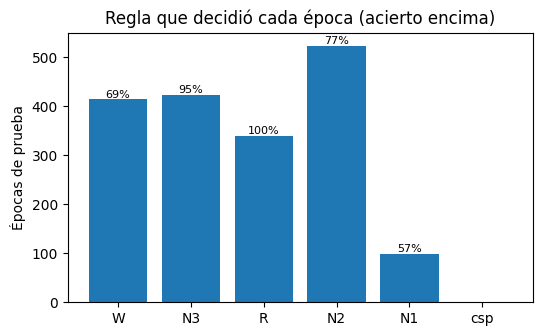

In [62]:
modelo = modelos["reglas"]
decisiones = [modelo.clasificar_epocas(t) for t in prueba]
y_reglas = np.concatenate([e for e, _ in decisiones])
regla = np.concatenate([r for _, r in decisiones])
validas = y_real != SIN_ANOTAR

uso = []
for i, nombre in enumerate(reglas.REGLAS):
    elegidas = validas & (regla == i)
    uso.append({"regla": nombre, "épocas": int(elegidas.sum()),
                "aciertos": float((y_reglas[elegidas] == y_real[elegidas]).mean()) if elegidas.any() else np.nan})
uso = pd.DataFrame(uso)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(uso["regla"], uso["épocas"])
for x, (n, acierto) in enumerate(zip(uso["épocas"], uso["aciertos"])):
    if n:
        ax.text(x, n, f"{acierto:.0%}", ha="center", va="bottom", fontsize=8)
ax.set(ylabel="Épocas de prueba", title="Regla que decidió cada época (acierto encima)")
guardar(fig, "c_uso_reglas")
uso

### Matrices de confusión

Las **filas** son lo que dijeron los técnicos y las **columnas**, lo que dijo el clasificador. Cada fila está normalizada; entre paréntesis va la cantidad de épocas.

- La **diagonal** son los aciertos (la sensibilidad de cada estadio).
- **Fuera de la diagonal** se ve con qué se confunde cada estadio. Por ejemplo, la casilla fila N1, columna N2 son las épocas N1 que el clasificador llamó N2.

Se muestran sin suavizado y con suavizado, para ver qué confusiones corrige el suavizado.

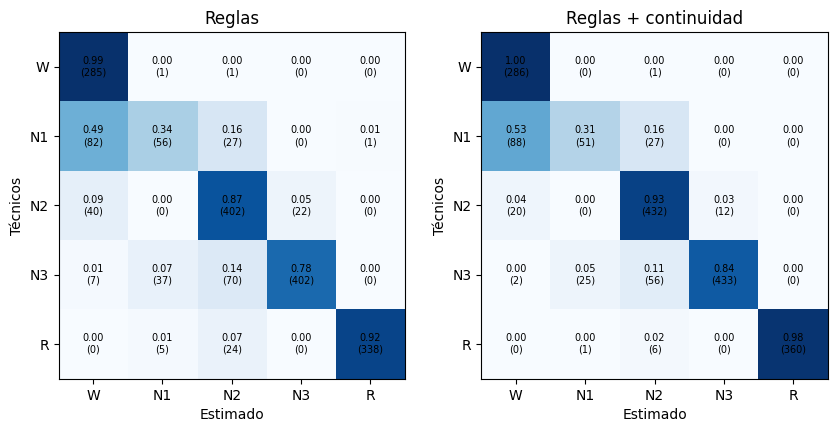

In [63]:
def graficar_confusion(matriz, ax, titulo):
    normalizada = matriz / matriz.sum(axis=1, keepdims=True).clip(min=1)
    ax.imshow(normalizada, cmap="Blues", vmin=0, vmax=1)
    for i in range(N_ESTADIOS):
        for j in range(N_ESTADIOS):
            ax.text(j, i, f"{normalizada[i, j]:.2f}\n({matriz[i, j]})", ha="center", va="center", fontsize=7)
    ax.set_xticks(range(N_ESTADIOS), NOMBRES_ESTADIOS)
    ax.set_yticks(range(N_ESTADIOS), NOMBRES_ESTADIOS)
    ax.set(xlabel="Estimado", ylabel="Técnicos", title=titulo)

fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
graficar_confusion(reportes["ninguno"]["confusion"], axs[0], "Reglas")
graficar_confusion(reportes["reglas"]["confusion"], axs[1], "Reglas + continuidad")
guardar(fig, "c_matrices_confusion")

### Hipnograma de un paciente de prueba

Tres hipnogramas del mismo paciente, uno debajo del otro: técnicos, reglas, y reglas con suavizado. El eje vertical sigue el orden habitual: W arriba, después REM, N1, N2 y N3 abajo.

Es la figura más intuitiva del informe: se ve cómo las reglas solas tienen "saltos" sueltos y cómo el suavizado los limpia.

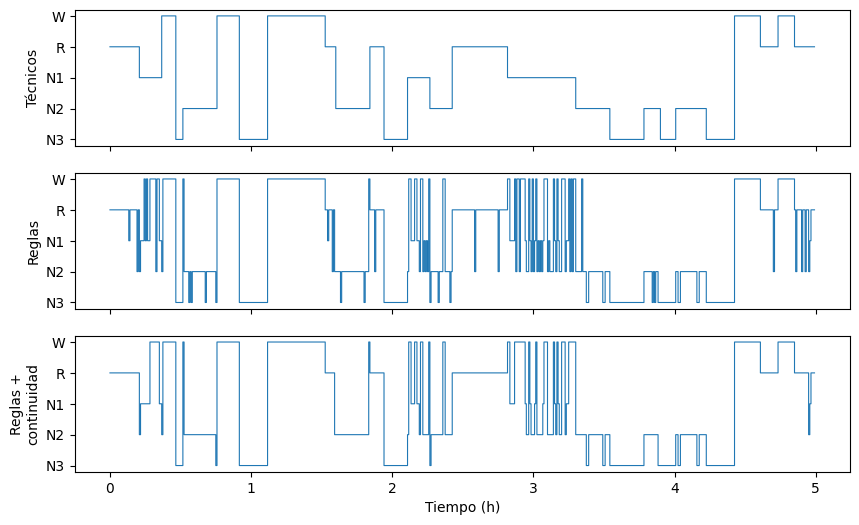

In [64]:
ORDEN = {0: 4, 4: 3, 1: 2, 2: 1, 3: 0}  # W arriba, REM debajo, después N1, N2, N3

def a_altura(y):
    return np.array([ORDEN.get(int(e), np.nan) for e in y])

tabla = prueba[0]
horas = np.arange(len(tabla.estadios)) * 30 / 3600
fig, axs = plt.subplots(3, 1, figsize=(10, 6), sharex=True, sharey=True)
for ax, y, titulo in zip(axs,
                         [tabla.estadios, modelos["ninguno"].predecir(tabla), modelos["reglas"].predecir(tabla)],
                         ["Técnicos", "Reglas", "Reglas +\ncontinuidad"]):
    ax.step(horas, a_altura(y), where="post", lw=0.8)
    ax.set_ylabel(titulo)
axs[0].set_yticks([4, 3, 2, 1, 0], ["W", "R", "N1", "N2", "N3"])
axs[-1].set_xlabel("Tiempo (h)")
guardar(fig, f"c_hipnograma_{tabla.id}")

## κ por paciente

Un boxplot del κ de cada paciente de prueba, con líneas de referencia en 0,74 (acuerdo entre técnicos del HMC) y 0,79 (red neuronal de referencia).

Muestra si el clasificador anda parecido en todos los pacientes o si hay algunos donde falla mucho, por ejemplo por un mal registro. Si aparece un paciente muy por debajo del resto, conviene mirar su hipnograma en la interfaz para entender por qué.

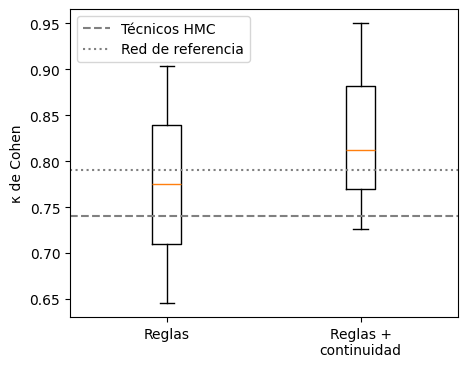

In [65]:
kappas = {nombre: [metricas.kappa(t.estadios, modelos[s].predecir(t)) for t in prueba]
          for nombre, s in [("Reglas", "ninguno"), ("Reglas +\ncontinuidad", "reglas")]}
fig, ax = plt.subplots(figsize=(5, 4))
ax.boxplot(list(kappas.values()), tick_labels=list(kappas))
ax.axhline(0.74, ls="--", c="gray", label="Técnicos HMC")
ax.axhline(0.79, ls=":", c="gray", label="Red de referencia")
ax.set_ylabel("κ de Cohen")
ax.legend()
guardar(fig, "c_kappa_por_paciente")